In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [43]:
df=pd.read_csv('/content/placement_data.csv')

In [44]:
df.head()

,Id,CGPA,Package (LPA)
0,1,6.84,3.92
1,2,9.66,8.53
2,3,8.59,7.07
3,4,7.93,3.39
4,5,5.76,2.00


In [45]:
df.describe()

,Id,CGPA,Package (LPA)
count,100.000000,100.000000,100.000000
mean,50.500000,7.303900,4.798700
std,29.011492,1.457774,2.484963
min,1.000000,5.030000,2.000000
25%,25.750000,5.947500,2.330000
50%,50.500000,7.270000,4.315000
75%,75.250000,8.582500,6.875000
max,100.000000,9.840000,10.350000


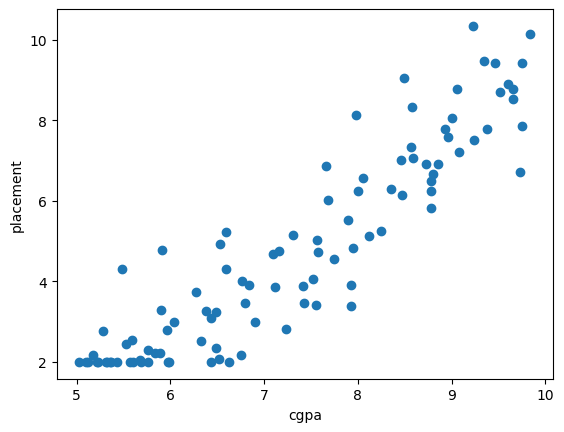

In [46]:
plt.scatter(df['CGPA'],df['Package (LPA)'])
plt.xlabel('cgpa')
plt.ylabel('placement')
plt.show()

In [47]:
x=df.iloc[:,1:2]
y=df.iloc[:,-1]

In [48]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=2)

In [49]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()
lr.fit(x_train,y_train)

LinearRegression()

In [50]:
x_test

,CGPA
83,5.31
30,7.98
56,5.43
24,7.23
16,6.49
23,6.80
2,8.59
27,7.52
28,7.90
13,6.04


In [51]:
y_test

,Package (LPA)
83,2.00
30,8.13
56,2.00
24,2.82
16,2.34
23,3.46
2,7.07
27,4.07
28,5.53
13,2.99


In [52]:
lr.predict(x_test.iloc[4].values.reshape(1,1))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([3.60391503])

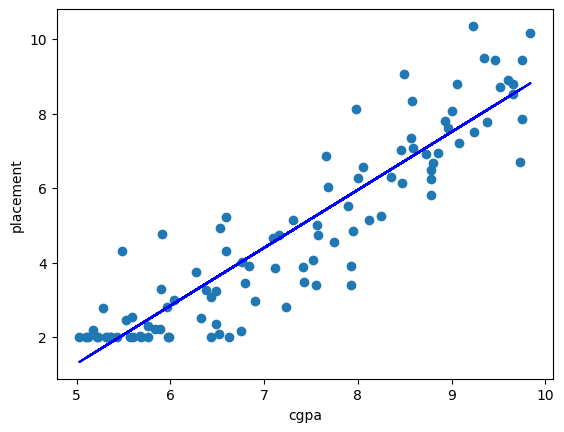

In [53]:
plt.scatter(df['CGPA'],df['Package (LPA)'])
plt.plot(x_train,lr.predict(x_train),color='blue')
plt.xlabel('cgpa')
plt.ylabel('placement')
plt.show()

In [54]:
#slope of the Line
m=lr.coef_

In [55]:
#Y=M*X + C
c=lr.intercept_

**Regression Metrices**


In [56]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [57]:
y_prid=lr.predict(x_test)

In [58]:
print("MAE",mean_absolute_error(y_test,y_prid))
print("MSE",mean_squared_error(y_test,y_prid))
print("RMSE",np.sqrt(mean_squared_error(y_test,y_prid)))
print("R2 Score",r2_score(y_test,y_prid)*100)

MAE 0.6992932461060162
MSE 0.9953429258527212
RMSE 0.9976687455527116
R2 Score 73.60840273880302


In [59]:
#adjusted R2 score
r2=r2_score(y_test,y_prid)
n=x_test.shape[0]
p=x_test.shape[1]
adjusted_r2=1-(1-r2)*(n-1)/(n-p-1)
adjusted_r2

0.7214220289095874